**Libraries import**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


**Load the dataset**

In [2]:

# Load all 14 CSV files

results = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv',
    na_values=[r'\N']
)

races = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv',
    na_values=[r'\N']
)

drivers = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv',
    na_values=[r'\N']
)

constructors = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv',
    na_values=[r'\N']
)

qualifying = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv',
    na_values=[r'\N']
)

status = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv',
    na_values=[r'\N']
)

circuits = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv',
    na_values=[r'\N']
)

constructor_results = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv',
    na_values=[r'\N']
)

constructor_standings = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv',
    na_values=[r'\N']
)

driver_standings = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv',
    na_values=[r'\N']
)

lap_times = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv',
    na_values=[r'\N']
)

pit_stops = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv',
    na_values=[r'\N']
)

sprint_results = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv',
    na_values=[r'\N']
)

seasons = pd.read_csv(
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv',
    na_values=[r'\N'] # replace empty values with \N
)


tables = {
    'results': results,
    'races': races,
    'drivers': drivers,
    'constructors': constructors,
    'qualifying': qualifying,
    'status': status,
    'circuits': circuits,
    'constructor_results': constructor_results,
    'constructor_standings': constructor_standings,
    'driver_standings': driver_standings,
    'lap_times': lap_times,
    'pit_stops': pit_stops,
    'sprint_results': sprint_results,
    'seasons': seasons
}

# Check that all tables are loaded
print("Number of tables:", len(tables))

for name, df in tables.items():
    print(name, ":", df.shape)


Number of tables: 14
results : (26759, 18)
races : (1125, 18)
drivers : (861, 9)
constructors : (212, 5)
qualifying : (10494, 9)
status : (139, 2)
circuits : (77, 9)
constructor_results : (12625, 5)
constructor_standings : (13391, 7)
driver_standings : (34863, 7)
lap_times : (589081, 6)
pit_stops : (11371, 7)
sprint_results : (360, 16)
seasons : (75, 2)


**Inspect results' data**

In [3]:
results.head() # Display the first five rows
results.info() # Check data types, non-null counts and columns
results.describe() # Statistical summary
results.isnull().sum() # Count missing values per column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

**Inspect duplicates in results.csv**

In [4]:
# Check completely identical rows
print("Exact duplicates:", results.duplicated().sum())

# Check drivers appearing more than once in the same race
print(
    "Duplicate driver-race combinations:",
    results.duplicated(
        subset=['raceId', 'driverId']
    ).sum()
)

Exact duplicates: 0
Duplicate driver-race combinations: 91


In [5]:
duplicates = results[
    results.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    )
].copy()

# Display the important columns
display(
    duplicates[
        ['resultId', 'raceId', 'driverId',
         'constructorId', 'grid', 'positionOrder',
         'points', 'statusId']
    ].sort_values(['raceId', 'driverId'])
)


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,statusId
13188,13189,540,229,54,0,26,0.0,81
13191,13192,540,229,57,0,29,0.0,97
17362,17363,717,373,172,1,7,0.0,60
24298,24304,717,373,172,1,12,0.0,98
17740,17741,733,465,172,0,22,0.0,54
...,...,...,...,...,...,...,...,...
20181,20182,838,627,154,15,6,0.0,18
20163,20164,839,579,51,1,15,1.0,6
20183,20184,839,579,51,7,13,0.0,5
20165,20166,839,647,6,2,17,0.0,5


In [6]:

# Add the race year
duplicates_details = pd.merge(
    duplicates,
    races[['raceId', 'year', 'name']],
    on='raceId',
    how='left'
)

# Add driver names
duplicates_details = pd.merge(
    duplicates_details,
    drivers[['driverId', 'forename', 'surname']],
    on='driverId',
    how='left'
)

# Add constructor names to duplicated records
duplicates_details = pd.merge(
    duplicates_details,
    constructors[['constructorId', 'name']],
    on='constructorId',
    how='left',
    suffixes=('', '_constructor')
)

# Display the results
display(
    duplicates_details[
        ['year', 'name', 'forename', 'surname',
         'raceId', 'driverId', 'constructorId', 'name_constructor', 'resultId',
         'grid', 'positionOrder', 'points']
    ].sort_values(['year', 'raceId', 'driverId'])
    .head(30)
)

# Count duplicate groups with multiple constructors
constructor_counts = (
    duplicates.groupby(['raceId', 'driverId'])
    ['constructorId'].nunique()
)

print(
    "Groups with different constructors:",
    (constructor_counts > 1).sum()
)

print(
    "Groups with the same constructor:",
    (constructor_counts == 1).sum()
)

# Check for multiple non-zero grid positions
grid_counts = (
    duplicates[duplicates['grid'] > 0]
    .groupby(['raceId', 'driverId'])
    .size()
)

print(
    "Groups with multiple positive grid positions:",
    (grid_counts > 1).sum()
)

# Check duplicate groups with conflicting podium outcomes
podium_counts = (
    duplicates.assign(
        podium=(duplicates['positionOrder'] <= 3).astype(int)
    )
    .groupby(['raceId', 'driverId'])
    ['podium'].nunique()
)

print(
    "Groups with conflicting podium labels:",
    (podium_counts > 1).sum()
)



,year,name,forename,surname,raceId,driverId,constructorId,name_constructor,resultId,grid,positionOrder,points
84,1950,Indianapolis 500,Tony,Bettenhausen,835,529,150,Deidt,20097,8,31,0.0
88,1950,Indianapolis 500,Tony,Bettenhausen,835,529,113,Kurtis Kraft,20179,9,5,1.0
85,1950,French Grand Prix,Louis,Rosier,838,627,154,Talbot-Lago,20143,6,12,0.0
89,1950,French Grand Prix,Louis,Rosier,838,627,154,Talbot-Lago,20182,15,6,0.0
86,1950,Italian Grand Prix,Juan,Fangio,839,579,51,Alfa Romeo,20164,1,15,1.0
91,1950,Italian Grand Prix,Juan,Fangio,839,579,51,Alfa Romeo,20184,7,13,0.0
87,1950,Italian Grand Prix,Alberto,Ascari,839,647,6,Ferrari,20166,2,17,0.0
90,1950,Italian Grand Prix,Alberto,Ascari,839,647,6,Ferrari,20183,6,2,3.0
81,1951,French Grand Prix,Juan,Fangio,828,579,51,Alfa Romeo,19928,1,11,0.0
92,1951,French Grand Prix,Juan,Fangio,828,579,51,Alfa Romeo,20186,7,1,5.0


Groups with different constructors: 16
Groups with the same constructor: 69
Groups with multiple positive grid positions: 82
Groups with conflicting podium labels: 21


**Primary keys check**

In [7]:

primary_keys = {
    'results': ['resultId'],
    'races': ['raceId'],
    'drivers': ['driverId'],
    'constructors': ['constructorId'],
    'qualifying': ['qualifyId'],
    'status': ['statusId'],
    'circuits': ['circuitId'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'driver_standings': ['driverStandingsId'],
    'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'sprint_results': ['resultId'],
    'seasons': ['year']
}


In [8]:

for table_name, key_columns in primary_keys.items():

    df = tables[table_name]

    # Count rows with at least one missing key component
    missing_keys = df[key_columns].isnull().any(axis=1).sum()

    # Count repeated keys
    duplicate_keys = df.duplicated(
        subset=key_columns
    ).sum()

    print("Table:", table_name)
    print("Primary key:", key_columns)
    print("Missing key rows:", missing_keys)
    print("Duplicate keys:", duplicate_keys)
    print("-" * 45)


Table: results
Primary key: ['resultId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: races
Primary key: ['raceId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: drivers
Primary key: ['driverId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: constructors
Primary key: ['constructorId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: qualifying
Primary key: ['qualifyId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: status
Primary key: ['statusId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: circuits
Primary key: ['circuitId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: constructor_results
Primary key: ['constructorResultsId']
Missing key rows: 0
Duplicate keys: 0
-----------

**Foreign keys check**

In [9]:

foreign_keys = {
    'results': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId'),
        ('statusId', 'status', 'statusId')
    ],

    'races': [
        ('year', 'seasons', 'year'),
        ('circuitId', 'circuits', 'circuitId')
    ],

    'qualifying': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'constructor_results': [
        ('raceId', 'races', 'raceId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'constructor_standings': [
        ('raceId', 'races', 'raceId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'driver_standings': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'lap_times': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'pit_stops': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'sprint_results': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId'),
        ('statusId', 'status', 'statusId')
    ]
}


In [10]:

foreign_key_results = []

for table_name, relationships in foreign_keys.items():

    df = tables[table_name]

    for foreign_key, ref_table, primary_key in relationships:

        # Count missing foreign keys
        missing_count = df[foreign_key].isnull().sum()

        # Check whether IDs exist in the referenced table
        invalid = (
            ~df[foreign_key].isin(tables[ref_table][primary_key])
        ) & df[foreign_key].notna()

        invalid_count = invalid.sum()

        foreign_key_results.append({
            'Table': table_name,
            'Foreign Key': foreign_key,
            'References': ref_table,
            'Missing Values': missing_count,
            'Invalid References': invalid_count
        })

fk_audit = pd.DataFrame(foreign_key_results)

display(fk_audit)


,Table,Foreign Key,References,Missing Values,Invalid References
0,results,raceId,races,0,0
1,results,driverId,drivers,0,0
2,results,constructorId,constructors,0,0
3,results,statusId,status,0,0
4,races,year,seasons,0,0
5,races,circuitId,circuits,0,0
6,qualifying,raceId,races,0,0
7,qualifying,driverId,drivers,0,0
8,qualifying,constructorId,constructors,0,0
9,constructor_results,raceId,races,0,0


**Count missing values**

In [11]:

for name, df in tables.items():

    print("\nTable:", name)

    missing = df.isnull().sum()

    print(
        missing[missing > 0]
        .sort_values(ascending=False)
    )

    print("-" * 45)



Table: results
milliseconds       19079
time               19079
fastestLapTime     18507
fastestLap         18507
fastestLapSpeed    18507
rank               18249
position           10953
number                 6
dtype: int64
---------------------------------------------

Table: races
sprint_time    1110
sprint_date    1107
fp3_time       1072
quali_time     1057
fp2_time       1057
fp1_time       1057
fp3_date       1053
fp2_date       1035
fp1_date       1035
quali_date     1035
time            731
dtype: int64
---------------------------------------------

Table: drivers
number    802
code      757
dtype: int64
---------------------------------------------

Table: constructors
Series([], dtype: int64)
---------------------------------------------

Table: qualifying
q3    6865
q2    4647
q1     156
dtype: int64
---------------------------------------------

Table: status
Series([], dtype: int64)
---------------------------------------------

Table: circuits
Series([], dtype: int64

**Qualifying coverage**

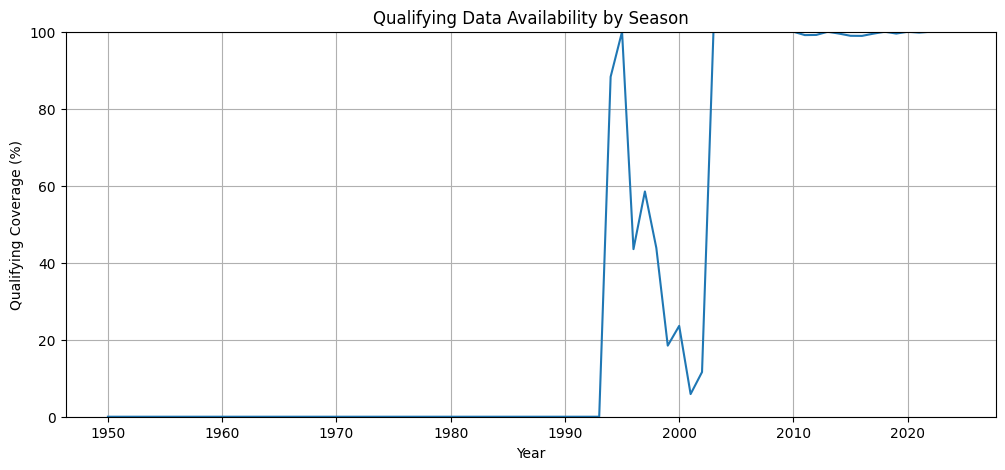

In [12]:

# Get race year for each result
results_years = pd.merge(
    results,
    races[['raceId', 'year']],
    on='raceId',
    how='left'
)

# Get unique driver-race combinations with qualifying data
qualifying_pairs = qualifying[
    ['raceId', 'driverId']
].drop_duplicates()

qualifying_pairs['has_qualifying'] = 1

# Match qualifying availability to result records
qualifying_coverage = pd.merge(
    results_years,
    qualifying_pairs,
    on=['raceId', 'driverId'],
    how='left'
)

# Missing match means no qualifying record
qualifying_coverage['has_qualifying'] = (
    qualifying_coverage['has_qualifying'].fillna(0)
)

# Percentage with qualifying data each year
coverage_by_year = (
    qualifying_coverage.groupby('year')['has_qualifying']
    .mean() * 100
)

plt.figure(figsize=(12, 5))
coverage_by_year.plot()

plt.title('Qualifying Data Availability by Season')
plt.xlabel('Year')
plt.ylabel('Qualifying Coverage (%)')
plt.ylim(0, 100)
plt.grid(True)
plt.show()


**Check grid values**

In [13]:
# Check minimum and maximum grid positions
print("Minimum grid position:", results['grid'].min())
print("Maximum grid position:", results['grid'].max())

# Count unusual grid values
print("Grid = 0:", (results['grid'] == 0).sum())
print("Negative grid values:", (results['grid'] < 0).sum())

# Display grid distribution
print(results['grid'].value_counts().sort_index())



# Select records where grid is zero
grid_zero = results[results['grid'] == 0].copy()

# Add race status descriptions
grid_zero = pd.merge(
    grid_zero,
    status,
    on='statusId',
    how='left',
    validate='many_to_one'
)

# Display the most common statuses
print(grid_zero['status'].value_counts().head(20))


Minimum grid position: 0
Maximum grid position: 34
Grid = 0: 1638
Negative grid values: 0
grid
0     1638
1     1136
2     1125
3     1130
4     1132
5     1132
6     1125
7     1135
8     1129
9     1132
10    1130
11    1132
12    1127
13    1125
14    1120
15    1113
16    1100
17    1089
18    1050
19    1031
20     975
21     697
22     656
23     453
24     429
25     301
26     248
27      46
28      30
29      25
30      19
31      18
32      17
33      13
34       1
Name: count, dtype: int64
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Disqualified             6
Retired                  3
Collision damage         3
Brakes                   2
Injured                  2
Safety concerns          2
107% Rule                2
Suspension               2
P

In [14]:
# Display all status values for grid-zero records
grid_zero_status = grid_zero['status'].value_counts()

display(grid_zero_status)


status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Disqualified             6
Retired                  3
Collision damage         3
Brakes                   2
Injured                  2
Safety concerns          2
107% Rule                2
Suspension               2
Power Unit               2
Fuel system              2
Underweight              1
Fatal accident           1
Battery                  1
Transmission             1
Gearbox                  1
Collision                1
Undertray                1
Hydraulics               1
Name: count, dtype: int64

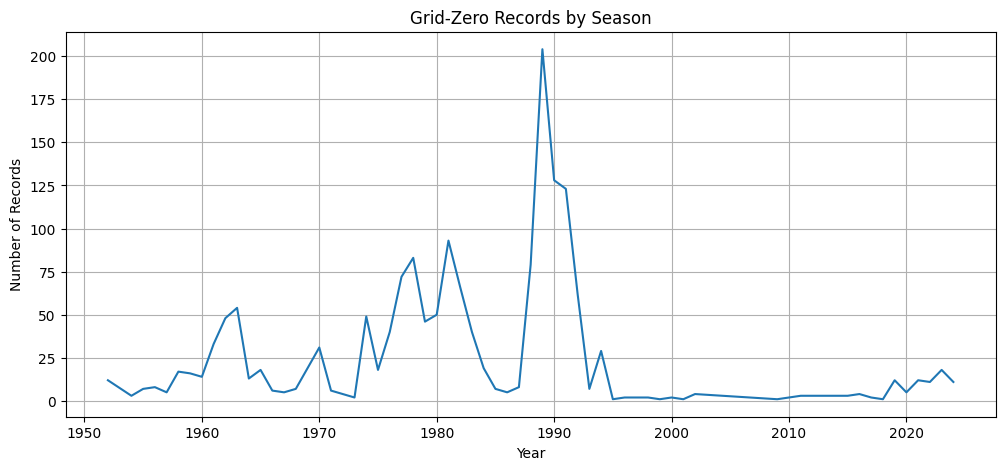

In [15]:
# Add year to grid-zero records
grid_zero_years = pd.merge(
    grid_zero,
    races[['raceId', 'year']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

# Calculate number of grid-zero records per year
grid_zero_counts = (
    grid_zero_years['year']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

grid_zero_counts.plot()

plt.title('Grid-Zero Records by Season')
plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.grid(True)
plt.show()


> Treat qualifying position as an optional additional feature and compare whether it improves model performance.

**Investigate grid = 0**

In [16]:
#Inspect the grid-zero drivers who finished
grid_zero_finished = grid_zero[
    grid_zero['status'].str.match(
        r'^(Finished|\+\d+ Laps?)$',
        na=False
    )
]

display(
    grid_zero_finished[
        ['raceId', 'driverId', 'grid',
         'positionOrder', 'status']
    ].head(20)
)

print(
    "Grid-zero records classified as finished/lapped:",
    len(grid_zero_finished)
)


,raceId,driverId,grid,positionOrder,status
1558,931,832,0,10,Finished
1569,1012,848,0,10,+1 Lap
1570,1013,8,0,10,+1 Lap
1571,1013,9,0,16,+2 Laps
1573,1014,807,0,13,Finished
1574,1016,825,0,17,+2 Laps
1575,1018,847,0,18,+2 Laps
1576,1022,9,0,17,+1 Lap
1577,1023,8,0,15,+1 Lap
1578,1025,848,0,5,Finished


Grid-zero records classified as finished/lapped: 56


In [17]:
# Exclude the three dominant non-starting status categories
other_grid_zero = grid_zero[
    ~grid_zero['status'].isin([
        'Did not qualify',
        'Did not prequalify',
        'Withdrew'
    ])
].copy()

print("Other grid-zero records:", len(other_grid_zero))

# Inspect completed laps and race classifications
display(
    other_grid_zero[
        ['raceId', 'driverId', 'grid', 'laps',
         'positionOrder', 'status']
    ].sort_values('laps', ascending=False).head(30)
)

print("Records with laps > 0:",
      (other_grid_zero['laps'] > 0).sum())

print("Records with laps = 0:",
      (other_grid_zero['laps'] == 0).sum())


Other grid-zero records: 130


,raceId,driverId,grid,laps,positionOrder,status
1558,931,832,0,78,10,Finished
1616,1111,825,0,72,16,Finished
1593,1064,815,0,71,8,+1 Lap
1632,1135,825,0,71,18,+1 Lap
1602,1084,822,0,70,11,+1 Lap
1635,1140,839,0,70,13,+1 Lap
1627,1129,822,0,70,13,Finished
1594,1064,849,0,70,16,+2 Laps
1613,1107,856,0,70,17,+1 Lap
1597,1071,8,0,70,12,+1 Lap


Records with laps > 0: 72
Records with laps = 0: 58


In [18]:

# Select grid-zero records with zero completed laps
grid_zero_no_laps = other_grid_zero[
    other_grid_zero['laps'] == 0
].copy()

print("Number of records:", len(grid_zero_no_laps))

# Count the different statuses
print(grid_zero_no_laps['status'].value_counts())


# Add year to the ambiguous records
grid_zero_no_laps = pd.merge(
    grid_zero_no_laps,
    races[['raceId', 'year']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

display(
    grid_zero_no_laps[
        ['year', 'raceId', 'driverId',
         'grid', 'laps', 'positionOrder', 'status']
    ].sort_values('year')
)


Number of records: 58
status
Accident           18
Injury              8
Excluded            6
Disqualified        6
Engine              6
Safety concerns     2
107% Rule           2
Fuel system         2
Injured             2
Underweight         1
Suspension          1
Fatal accident      1
Retired             1
Battery             1
Brakes              1
Name: count, dtype: int64


,year,raceId,driverId,grid,laps,positionOrder,status
51,1954,807,581,0,0,22,Accident
50,1954,805,626,0,0,17,Accident
49,1956,785,589,0,0,18,Engine
47,1956,785,578,0,0,16,Engine
48,1956,785,479,0,0,17,Engine
46,1958,772,526,0,0,26,Engine
45,1960,754,547,0,0,17,Fuel system
52,1963,728,310,0,0,21,Accident
44,1964,710,408,0,0,18,Accident
43,1966,695,389,0,0,19,Injury


Data types and time formats

In [19]:
# Inspect date and time-related columns

print("Races:")
print(races[['date', 'time']].dtypes)

print("\nQualifying:")
print(qualifying[['q1', 'q2', 'q3']].dtypes)

print("\nLap times:")
print(lap_times[['time', 'milliseconds']].dtypes)

print("\nPit stops:")
print(pit_stops[['time', 'duration', 'milliseconds']].dtypes)



display(races[['date', 'time']].head())

display(qualifying[['q1', 'q2', 'q3']].head())

display(lap_times[['time', 'milliseconds']].head())

display(pit_stops[['time', 'duration', 'milliseconds']].head())


Races:
date    object
time    object
dtype: object

Qualifying:
q1    object
q2    object
q3    object
dtype: object

Lap times:
time            object
milliseconds     int64
dtype: object

Pit stops:
time            object
duration        object
milliseconds     int64
dtype: object


,date,time
0,2009-03-29,06:00:00
1,2009-04-05,09:00:00
2,2009-04-19,07:00:00
3,2009-04-26,12:00:00
4,2009-05-10,12:00:00


,q1,q2,q3
0,1:26.572,1:25.187,1:26.714
1,1:26.103,1:25.315,1:26.869
2,1:25.664,1:25.452,1:27.079
3,1:25.994,1:25.691,1:27.178
4,1:25.960,1:25.518,1:27.236


,time,milliseconds
0,1:38.109,98109
1,1:33.006,93006
2,1:32.713,92713
3,1:32.803,92803
4,1:32.342,92342


,time,duration,milliseconds
0,17:05:23,26.898,26898
1,17:05:52,25.021,25021
2,17:20:48,23.426,23426
3,17:22:34,23.251,23251
4,17:24:10,23.842,23842


In [20]:

# Convert dates temporarily to check validity
race_dates_check = pd.to_datetime(
    races['date'],
    errors='coerce'
)

print("Original missing dates:", races['date'].isnull().sum())

print("Invalid dates after conversion:", race_dates_check.isnull().sum())

print("Earliest date:", race_dates_check.min())
print("Latest date:", race_dates_check.max())


Original missing dates: 0
Invalid dates after conversion: 0
Earliest date: 1950-05-13 00:00:00
Latest date: 2024-12-08 00:00:00


In [21]:

# Temporary copy for auditing
qualifying_check = qualifying.copy()

for column in ['q1', 'q2', 'q3']:

    # Convert qualifying lap time to timedelta
    converted = pd.to_timedelta(
        '00:' + qualifying_check[column].dropna().astype(str),
        errors='coerce'
    )

    # Store durations in seconds
    qualifying_check[column + '_seconds'] = np.nan

    qualifying_check.loc[
        converted.index,
        column + '_seconds'
    ] = converted.dt.total_seconds()

    print(column)
    print("Original non-missing:", qualifying[column].notna().sum())
    print("Successfully converted:", converted.notna().sum())
    print("Invalid formats:", converted.isna().sum())
    print("-" * 40)

display(
    qualifying_check[
        ['q1', 'q1_seconds',
         'q2', 'q2_seconds',
         'q3', 'q3_seconds']
    ].head()
)



# Work on a temporary copy
lap_times_check = lap_times.copy()

# Convert milliseconds to seconds
lap_times_check['time_seconds'] = (
    lap_times_check['milliseconds'] / 1000
)

# Display original and converted values
display(
    lap_times_check[
        ['time', 'milliseconds', 'time_seconds']
    ].head()
)



# Parse the original lap-time strings
parsed_lap_times = pd.to_timedelta(
    '00:' + lap_times['time'].astype(str),
    errors='coerce'
).dt.total_seconds()

# Compare parsed times with milliseconds
differences = (
    parsed_lap_times -
    lap_times_check['time_seconds']
).abs()

print("Unparseable lap times:", parsed_lap_times.isnull().sum())

print(
    "Time mismatches:",
    (differences > 0.001).sum()
)



pit_stops_check = pit_stops.copy()

# Convert duration strings to numeric seconds
pit_stops_check['duration_seconds'] = pd.to_numeric(
    pit_stops_check['duration'],
    errors='coerce'
)

# Convert milliseconds to seconds
pit_stops_check['milliseconds_seconds'] = (
    pit_stops_check['milliseconds'] / 1000
)

# Compare the two duration representations
differences = (
    pit_stops_check['duration_seconds'] -
    pit_stops_check['milliseconds_seconds']
).abs()

print(
    "Invalid duration strings:",
    pit_stops_check['duration_seconds'].isnull().sum()
)

print(
    "Duration mismatches:",
    (differences > 0.001).sum()
)

display(
    pit_stops_check[
        ['duration', 'milliseconds',
         'duration_seconds', 'milliseconds_seconds']
    ].head()
)


q1
Original non-missing: 10338
Successfully converted: 10338
Invalid formats: 0
----------------------------------------
q2
Original non-missing: 5847
Successfully converted: 5847
Invalid formats: 0
----------------------------------------
q3
Original non-missing: 3629
Successfully converted: 3629
Invalid formats: 0
----------------------------------------


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


,time,milliseconds,time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


Unparseable lap times: 43
Time mismatches: 0
Invalid duration strings: 517
Duration mismatches: 0


,duration,milliseconds,duration_seconds,milliseconds_seconds
0,26.898,26898,26.898,26.898
1,25.021,25021,25.021,25.021
2,23.426,23426,23.426,23.426
3,23.251,23251,23.251,23.251
4,23.842,23842,23.842,23.842


In [22]:

# Temporary copy for auditing
qualifying_check = qualifying.copy()

for column in ['q1', 'q2', 'q3']:

    # Convert qualifying lap time to timedelta
    converted = pd.to_timedelta(
        '00:' + qualifying_check[column].dropna().astype(str),
        errors='coerce'
    )

    # Store durations in seconds
    qualifying_check[column + '_seconds'] = np.nan

    qualifying_check.loc[
        converted.index,
        column + '_seconds'
    ] = converted.dt.total_seconds()

    print(column)
    print("Original non-missing:", qualifying[column].notna().sum())
    print("Successfully converted:", converted.notna().sum())
    print("Invalid formats:", converted.isna().sum())
    print("-" * 40)

display(
    qualifying_check[
        ['q1', 'q1_seconds',
         'q2', 'q2_seconds',
         'q3', 'q3_seconds']
    ].head()
)



# Work on a temporary copy
lap_times_check = lap_times.copy()

# Convert milliseconds to seconds
lap_times_check['time_seconds'] = (
    lap_times_check['milliseconds'] / 1000
)

# Display original and converted values
display(
    lap_times_check[
        ['time', 'milliseconds', 'time_seconds']
    ].head()
)



# Parse the original lap-time strings
parsed_lap_times = pd.to_timedelta(
    '00:' + lap_times['time'].astype(str),
    errors='coerce'
).dt.total_seconds()

# Compare parsed times with milliseconds
differences = (
    parsed_lap_times -
    lap_times_check['time_seconds']
).abs()

print("Unparseable lap times:", parsed_lap_times.isnull().sum())

print(
    "Time mismatches:",
    (differences > 0.001).sum()
)



pit_stops_check = pit_stops.copy()

# Convert duration strings to numeric seconds
pit_stops_check['duration_seconds'] = pd.to_numeric(
    pit_stops_check['duration'],
    errors='coerce'
)

# Convert milliseconds to seconds
pit_stops_check['milliseconds_seconds'] = (
    pit_stops_check['milliseconds'] / 1000
)

# Compare the two duration representations
differences = (
    pit_stops_check['duration_seconds'] -
    pit_stops_check['milliseconds_seconds']
).abs()

print(
    "Invalid duration strings:",
    pit_stops_check['duration_seconds'].isnull().sum()
)

print(
    "Duration mismatches:",
    (differences > 0.001).sum()
)

display(
    pit_stops_check[
        ['duration', 'milliseconds',
         'duration_seconds', 'milliseconds_seconds']
    ].head()
)


q1
Original non-missing: 10338
Successfully converted: 10338
Invalid formats: 0
----------------------------------------
q2
Original non-missing: 5847
Successfully converted: 5847
Invalid formats: 0
----------------------------------------
q3
Original non-missing: 3629
Successfully converted: 3629
Invalid formats: 0
----------------------------------------


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


,time,milliseconds,time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


Unparseable lap times: 43
Time mismatches: 0
Invalid duration strings: 517
Duration mismatches: 0


,duration,milliseconds,duration_seconds,milliseconds_seconds
0,26.898,26898,26.898,26.898
1,25.021,25021,25.021,25.021
2,23.426,23426,23.426,23.426
3,23.251,23251,23.251,23.251
4,23.842,23842,23.842,23.842


In [23]:

invalid_pit_durations = pit_stops[
    pit_stops_check['duration_seconds'].isna() &
    pit_stops['duration'].notna()
]

print("Unparseable pit-stop durations:", len(invalid_pit_durations))

display(
    invalid_pit_durations[
        ['raceId', 'driverId', 'stop',
         'duration', 'milliseconds']
    ].head(30)
)

print(
    invalid_pit_durations['duration']
    .value_counts()
    .head(20)
)


Unparseable pit-stop durations: 517


,raceId,driverId,stop,duration,milliseconds
751,853,817,1,16:44.718,1004718
2419,881,814,2,2:03.124,123124
2420,881,16,2,1:29.401,89401
2421,881,18,3,1:44.833,104833
2422,884,16,1,1:14.026,74026
2533,888,17,1,2:42.042,162042
2713,893,154,3,1:13.009,73009
2802,894,16,3,1:11.445,71445
3089,901,817,3,1:49.329,109329
3159,903,13,1,1:18.277,78277


duration
24:16.349    2
2:03.124     1
6:29.973     1
6:32.517     1
6:33.601     1
6:36.504     1
6:36.837     1
6:41.057     1
6:41.749     1
6:42.478     1
6:40.857     1
6:40.463     1
6:42.029     1
6:46.256     1
6:47.553     1
6:47.673     1
6:27.399     1
50:11.861    1
51:05.174    1
51:09.017    1
Name: count, dtype: int64


In [24]:

# Lap-time milliseconds
print("Lap-time missing milliseconds:",
      lap_times['milliseconds'].isna().sum())

print("Lap-time non-positive milliseconds:",
      (lap_times['milliseconds'] <= 0).sum())

# Pit-stop milliseconds
print("Pit-stop missing milliseconds:",
      pit_stops['milliseconds'].isna().sum())

print("Pit-stop non-positive milliseconds:",
      (pit_stops['milliseconds'] <= 0).sum())

# Inspect the largest durations
display(
    lap_times.nlargest(10, 'milliseconds')[
        ['raceId', 'driverId', 'lap', 'time', 'milliseconds']
    ]
)

display(
    pit_stops.nlargest(10, 'milliseconds')[
        ['raceId', 'driverId', 'stop', 'duration', 'milliseconds']
    ]
)


Lap-time missing milliseconds: 0
Lap-time non-positive milliseconds: 0
Pit-stop missing milliseconds: 0
Pit-stop non-positive milliseconds: 0


,raceId,driverId,lap,time,milliseconds
8372,847,2,25,2:05:07.547,7507547
8020,847,13,25,2:05:06.656,7506656
8426,847,808,25,2:05:06.243,7506243
8621,847,155,25,2:05:06.095,7506095
7916,847,20,25,2:05:05.152,7505152
8089,847,17,25,2:05:05.034,7505034
7985,847,4,25,2:05:04.226,7504226
8495,847,814,25,2:05:03.980,7503980
8876,847,37,25,2:05:03.795,7503795
8234,847,18,25,2:05:03.775,7503775


,raceId,driverId,stop,duration,milliseconds
9156,1083,840,1,51:09.017,3069017
9155,1083,20,1,51:07.301,3067301
9157,1083,854,1,51:05.174,3065174
9154,1083,825,1,51:03.613,3063613
9152,1083,817,1,51:03.314,3063314
9151,1083,822,1,50:55.732,3055732
9147,1083,4,1,50:55.700,3055700
9150,1083,849,1,50:51.904,3051904
9153,1083,842,1,50:48.950,3048950
9145,1083,1,1,50:46.888,3046888


**Duration conversions**

In [25]:
# Preserve original datasets
races_clean = races.copy()
qualifying_clean = qualifying.copy()
lap_times_clean = lap_times.copy()
pit_stops_clean = pit_stops.copy()

In [26]:
# Convert race dates to datetime
races_clean['date'] = pd.to_datetime(
    races_clean['date'],
    errors='coerce'
)

print(races_clean['date'].dtype)
print("Missing dates:", races_clean['date'].isnull().sum())


datetime64[ns]
Missing dates: 0


In [27]:
# Convert qualifying times into seconds
for column in ['q1', 'q2', 'q3']:

    converted = pd.to_timedelta(
        '00:' + qualifying_clean[column].dropna().astype(str),
        errors='coerce'
    )

    qualifying_clean[column + '_seconds'] = (
        converted.dt.total_seconds()
    )

display(
    qualifying_clean[
        ['q1', 'q1_seconds',
         'q2', 'q2_seconds',
         'q3', 'q3_seconds']
    ].head()
)


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


In [28]:
# Convert milliseconds to seconds
lap_times_clean['time_seconds'] = (
    lap_times_clean['milliseconds'] / 1000
)

display(
    lap_times_clean[
        ['time', 'milliseconds', 'time_seconds']
    ].head()
)

print(
    "Missing converted lap times:",
    lap_times_clean['time_seconds'].isnull().sum()
)


,time,milliseconds,time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


Missing converted lap times: 0


In [29]:
# Convert pit-stop milliseconds to seconds
pit_stops_clean['duration_seconds'] = (
    pit_stops_clean['milliseconds'] / 1000
)

display(
    pit_stops_clean[
        ['duration', 'milliseconds', 'duration_seconds']
    ].head()
)

print(
    "Missing converted durations:",
    pit_stops_clean['duration_seconds'].isnull().sum()
)


,duration,milliseconds,duration_seconds
0,26.898,26898,26.898
1,25.021,25021,25.021
2,23.426,23426,23.426
3,23.251,23251,23.251
4,23.842,23842,23.842


Missing converted durations: 0


In [30]:

# 1. Verify race dates
print("Race dates:")
print("Data type:", races_clean['date'].dtype)
print("Missing:", races_clean['date'].isna().sum())

# 2. Verify qualifying conversions
print("\nQualifying times:")

for column in ['q1', 'q2', 'q3']:
    failed = (
        qualifying_clean[column].notna() &
        qualifying_clean[column + '_seconds'].isna()
    ).sum()

    print(column, "- unexpected failures:", failed)

# 3. Verify lap and pit-stop durations
print("\nLap times:")
print(
    "Invalid durations:",
    (
        lap_times_clean['time_seconds'].isna() |
        (lap_times_clean['time_seconds'] <= 0)
    ).sum()
)

print("\nPit stops:")
print(
    "Invalid durations:",
    (
        pit_stops_clean['duration_seconds'].isna() |
        (pit_stops_clean['duration_seconds'] <= 0)
    ).sum()
)

# 4. Verify row counts have not changed
print("\nRow-count verification:")

for name, original, cleaned in [
    ('races', races, races_clean),
    ('qualifying', qualifying, qualifying_clean),
    ('lap_times', lap_times, lap_times_clean),
    ('pit_stops', pit_stops, pit_stops_clean)
]:
    print(
        name,
        "- original:", len(original),
        "- cleaned:", len(cleaned)
    )
    assert len(original) == len(cleaned)


Race dates:
Data type: datetime64[ns]
Missing: 0

Qualifying times:
q1 - unexpected failures: 0
q2 - unexpected failures: 0
q3 - unexpected failures: 0

Lap times:
Invalid durations: 0

Pit stops:
Invalid durations: 0

Row-count verification:
races - original: 1125 - cleaned: 1125
qualifying - original: 10494 - cleaned: 10494
lap_times - original: 589081 - cleaned: 589081
pit_stops - original: 11371 - cleaned: 11371
